In [2]:
# ── Dependencies ─────────────────────────────────────────────────────────
import subprocess, sys
def _install(pkg):
    subprocess.check_call([sys.executable,'-m','pip','install','-q',pkg])
for pkg in ['rdkit','xgboost','imbalanced-learn','scikit-learn',
            'matplotlib','seaborn','openpyxl','torch','torch-geometric']:
    try: __import__(pkg.replace('-','_'))
    except ImportError: _install(pkg)
print('Dependencies OK.')

Dependencies OK.


In [3]:
# ── Imports ──────────────────────────────────────────────────────────────
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import copy

from rdkit import Chem
from rdkit.Chem import AllChem, DataStructs

from sklearn.model_selection import train_test_split, ParameterGrid, StratifiedKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score, average_precision_score, matthews_corrcoef,
    balanced_accuracy_score, f1_score, confusion_matrix,
    roc_curve, precision_recall_curve, classification_report
)
from xgboost import XGBClassifier
from scipy.stats import spearmanr, chi2_contingency

import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.nn import GCNConv, GATConv, GINConv, SAGEConv, global_mean_pool
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Device: cpu


---
## Step 1 — Shared Feature Engineering Helpers

In [4]:
# ── Canonicalisation ─────────────────────────────────────────────────────
def canonicalize(smi):
    try:
        mol = Chem.MolFromSmiles(str(smi))
        return Chem.MolToSmiles(mol) if mol else None
    except: return None

# ── ECFP4 (2048 bits) ────────────────────────────────────────────────────
def smiles_to_ecfp4(smi, radius=2, n_bits=2048):
    mol = Chem.MolFromSmiles(smi)
    if mol is None: return None
    fp  = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=n_bits)
    arr = np.zeros(n_bits, dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

# ── Atom / Bond features for GNN ─────────────────────────────────────────
ATOM_SYMBOLS = [6,7,8,16,9,15,17,35,53]  # C N O S F P Cl Br I

def one_hot(val, choices):
    vec = [0]*len(choices)
    try: vec[choices.index(val)] = 1
    except ValueError: pass
    return vec

from rdkit.Chem import rdchem
HYBRID_MAP = {
    rdchem.HybridizationType.SP  : 0,
    rdchem.HybridizationType.SP2 : 1,
    rdchem.HybridizationType.SP3 : 2,
}

def atom_feat(atom):
    at_oh  = one_hot(atom.GetAtomicNum(), ATOM_SYMBOLS) + [0]  # 10-dim
    hyb    = [0,0,0,0]
    hyb[HYBRID_MAP.get(atom.GetHybridization(), 3)] = 1
    deg    = min(atom.GetDegree(), 5)
    deg_oh = [0]*6; deg_oh[deg]=1
    fc     = atom.GetFormalCharge()
    fc_enc = [1 if fc<0 else 0, 1 if fc==0 else 0, 1 if fc>0 else 0]
    extras = [int(atom.GetIsAromatic()), int(atom.IsInRing()),
              min(atom.GetTotalNumHs(), 4) / 4.0, atom.GetMass() / 100.0]
    return at_oh + deg_oh + fc_enc + hyb + extras  # 27-dim

BOND_TYPES = [rdchem.BondType.SINGLE, rdchem.BondType.DOUBLE,
              rdchem.BondType.TRIPLE, rdchem.BondType.AROMATIC]

def bond_feat(bond):
    return one_hot(bond.GetBondType(), BOND_TYPES) + [
        int(bond.GetIsConjugated()), int(bond.IsInRing())]  # 6-dim

_mol = Chem.MolFromSmiles('CC(=O)O')
ATOM_DIM = len(atom_feat(_mol.GetAtomWithIdx(0)))
BOND_DIM  = len(bond_feat(_mol.GetBondWithIdx(0)))
print(f'Atom dim: {ATOM_DIM}  Bond dim: {BOND_DIM}')

def mol_to_graph(smi, label):
    mol = Chem.MolFromSmiles(smi)
    if mol is None: return None
    x = torch.tensor([atom_feat(a) for a in mol.GetAtoms()], dtype=torch.float)
    ei, ea = [], []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        bf = bond_feat(bond)
        ei += [[i,j],[j,i]]; ea += [bf, bf]
    if ei:
        edge_index = torch.tensor(ei, dtype=torch.long).t().contiguous()
        edge_attr  = torch.tensor(ea, dtype=torch.float)
    else:
        edge_index = torch.zeros((2,0), dtype=torch.long)
        edge_attr  = torch.zeros((0, BOND_DIM), dtype=torch.float)
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr,
                y=torch.tensor([label], dtype=torch.float))

print('Feature helpers defined.')

Atom dim: 27  Bond dim: 6
Feature helpers defined.


In [5]:
# ── Evaluation helper ────────────────────────────────────────────────────
def evaluate(y_true, y_prob, name, cpt=0.5):
    y_pred = (y_prob >= cpt).astype(int)
    tn,fp,fn,tp = confusion_matrix(y_true, y_pred).ravel()
    sens = tp/(tp+fn) if (tp+fn)>0 else 0
    spec = tn/(tn+fp) if (tn+fp)>0 else 0
    return {
        'Model'      : name,
        'CPT'        : cpt,
        'Sensitivity': round(sens*100,1),
        'Specificity': round(spec*100,1),
        'CCR'        : round((sens+spec)/2*100,1),
        'ROC-AUC'    : round(roc_auc_score(y_true, y_prob),4),
        'PR-AUC'     : round(average_precision_score(y_true, y_prob),4),
        'MCC'        : round(matthews_corrcoef(y_true, y_pred),4),
        'Bal-Acc'    : round(balanced_accuracy_score(y_true,y_pred)*100,1),
        'F1'         : round(f1_score(y_true,y_pred,zero_division=0),4),
        'TP':int(tp),'TN':int(tn),'FP':int(fp),'FN':int(fn)
    }

METRIC_COLS = ['Model','CPT','Sensitivity','Specificity','CCR',
               'ROC-AUC','PR-AUC','MCC','Bal-Acc','F1']
print('Evaluation helper defined.')

Evaluation helper defined.


In [6]:
# ── GNN Architecture (GCN/GAT/GIN/SAGE with residual connections) ────────
class MolGNN(nn.Module):
    def __init__(self, in_dim, hidden=128, n_layers=3, dropout=0.3,
                 conv_type='GCN', heads=4):
        super().__init__()
        self.drop = nn.Dropout(dropout)
        self.proj = nn.Linear(in_dim, hidden)
        self.bn0  = nn.BatchNorm1d(hidden)
        self.convs = nn.ModuleList()
        self.bns   = nn.ModuleList()
        for _ in range(n_layers):
            if conv_type == 'GCN':
                self.convs.append(GCNConv(hidden, hidden))
            elif conv_type == 'GAT':
                self.convs.append(GATConv(hidden, hidden, heads=heads,
                                          concat=False, dropout=dropout))
            elif conv_type == 'GIN':
                mlp = nn.Sequential(nn.Linear(hidden, hidden*2),
                                    nn.BatchNorm1d(hidden*2), nn.ReLU(),
                                    nn.Linear(hidden*2, hidden))
                self.convs.append(GINConv(mlp, train_eps=True))
            elif conv_type == 'SAGE':
                self.convs.append(SAGEConv(hidden, hidden))
            self.bns.append(nn.BatchNorm1d(hidden))
        self.head = nn.Sequential(nn.Linear(hidden, hidden//2), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(hidden//2, 1))

    def forward(self, x, edge_index, batch):
        x = F.relu(self.bn0(self.proj(x))); x = self.drop(x)
        for conv, bn in zip(self.convs, self.bns):
            x_res = x
            x = conv(x, edge_index); x = bn(x); x = F.relu(x); x = self.drop(x)
            x = x + x_res  # residual connection
        return self.head(global_mean_pool(x, batch)).squeeze(-1)

def gnn_train_epoch(model, loader, optimizer, criterion, device):
    model.train(); total_loss = 0
    for batch in loader:
        batch = batch.to(device); optimizer.zero_grad()
        loss = criterion(model(batch.x, batch.edge_index, batch.batch), batch.y)
        loss.backward(); optimizer.step()
        total_loss += loss.item() * batch.num_graphs
    return total_loss / len(loader.dataset)

@torch.no_grad()
def gnn_eval(model, loader, device):
    model.eval(); all_logits, all_labels = [], []
    for batch in loader:
        batch = batch.to(device)
        all_logits.append(model(batch.x, batch.edge_index, batch.batch).cpu())
        all_labels.append(batch.y.cpu())
    logits = torch.cat(all_logits).numpy()
    labels = torch.cat(all_labels).numpy().astype(int)
    probs  = torch.sigmoid(torch.tensor(logits)).numpy()
    return probs, labels, roc_auc_score(labels, probs)

GNN_CONFIGS = {
    'GCN' : [{'hidden':128,'n_layers':3,'dropout':0.3,'lr':0.001},
             {'hidden':256,'n_layers':3,'dropout':0.3,'lr':0.001},
             {'hidden':128,'n_layers':4,'dropout':0.4,'lr':0.0005}],
    'GAT' : [{'hidden':128,'n_layers':3,'dropout':0.3,'lr':0.001,'heads':4},
             {'hidden':128,'n_layers':3,'dropout':0.4,'lr':0.0005,'heads':8},
             {'hidden':256,'n_layers':3,'dropout':0.3,'lr':0.001,'heads':4}],
    'GIN' : [{'hidden':128,'n_layers':3,'dropout':0.3,'lr':0.001},
             {'hidden':256,'n_layers':3,'dropout':0.3,'lr':0.001},
             {'hidden':128,'n_layers':4,'dropout':0.4,'lr':0.0005}],
    'SAGE': [{'hidden':128,'n_layers':3,'dropout':0.3,'lr':0.001},
             {'hidden':256,'n_layers':3,'dropout':0.3,'lr':0.001},
             {'hidden':128,'n_layers':4,'dropout':0.4,'lr':0.0005}],
}
MAX_EPOCHS = 100; PATIENCE = 20; BATCH = 64
print(f'MolGNN defined. ATOM_DIM={ATOM_DIM}')

MolGNN defined. ATOM_DIM=27


In [7]:
# ── GNN Training Loop (shared by Mito and Caspase) ───────────────────────
def train_gnns(graphs_train, graphs_val, y_train, tag=''):
    pos_weight = torch.tensor([(y_train==0).sum()/(y_train==1).sum()], device=DEVICE)
    criterion  = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    train_ldr  = DataLoader(graphs_train, batch_size=BATCH, shuffle=True)
    val_ldr    = DataLoader(graphs_val,   batch_size=BATCH, shuffle=False)
    best_models, best_cfgs, best_val_aucs, history = {}, {}, {}, {}
    for arch, configs in GNN_CONFIGS.items():
        print(f'\n{"="*55}\n{tag} {arch}  ({len(configs)} configs)')
        best_auc, best_state, best_cfg = 0, None, {}
        for cfg in configs:
            heads = cfg.pop('heads', 4)
            model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                           dropout=cfg['dropout'], conv_type=arch, heads=heads).to(DEVICE)
            opt   = torch.optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=1e-5)
            sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt,'max',factor=0.5,patience=10)
            cfg['heads'] = heads
            best_ep_auc, no_imp, best_ep_state = 0, 0, None
            tr_aucs, va_aucs = [], []
            for _ in range(MAX_EPOCHS):
                gnn_train_epoch(model, train_ldr, opt, criterion, DEVICE)
                _, _, tr_a = gnn_eval(model, train_ldr, DEVICE)
                _, _, va_a = gnn_eval(model, val_ldr,   DEVICE)
                sched.step(va_a); tr_aucs.append(tr_a); va_aucs.append(va_a)
                if va_a > best_ep_auc:
                    best_ep_auc = va_a; best_ep_state = copy.deepcopy(model.state_dict()); no_imp = 0
                else: no_imp += 1
                if no_imp >= PATIENCE: break
            if best_ep_auc > best_auc:
                best_auc = best_ep_auc; best_state = best_ep_state
                best_cfg = cfg.copy(); history[arch] = (tr_aucs, va_aucs)
            print(f'  {cfg}  val AUC={best_ep_auc:.4f}  ep={len(tr_aucs)}')
        best_models[arch] = best_state; best_cfgs[arch] = best_cfg
        best_val_aucs[arch] = best_auc; print(f'>> Best {arch}: {best_auc:.4f}')
    return best_models, best_cfgs, best_val_aucs, history

def predict_gnns(best_models, best_cfgs, loader):
    probs = {}
    for arch, state in best_models.items():
        cfg = best_cfgs[arch]
        model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                       dropout=cfg['dropout'], conv_type=arch, heads=cfg.get('heads',4)).to(DEVICE)
        model.load_state_dict(state)
        p, _, _ = gnn_eval(model, loader, DEVICE); probs[arch] = p
    return probs

print('GNN training helpers defined.')

GNN training helpers defined.


---
## Step 2 — Mitochondrial Toxicity Model (AID_720635)
### 2a. Load & Curate

In [9]:
# ── Load AID_720635 ──────────────────────────────────────────────────────
df_mito_raw = pd.read_excel('/Users/yaminichitikela/Desktop/qsar casepase/mito/AID_720635_cleaned.xlsx',
    usecols=['PUBCHEM_CID','PUBCHEM_EXT_DATASOURCE_SMILES',
             'PUBCHEM_ACTIVITY_SCORE','PUBCHEM_ACTIVITY_OUTCOME'])
print(f'Raw rows : {len(df_mito_raw):,}')
print(df_mito_raw['PUBCHEM_ACTIVITY_OUTCOME'].value_counts())

df_mito_raw['csmi'] = df_mito_raw['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(canonicalize)
df_mito = df_mito_raw.dropna(subset=['csmi']).drop_duplicates('csmi', keep='first').reset_index(drop=True)

df_mito['label'] = df_mito['PUBCHEM_ACTIVITY_SCORE'].apply(
    lambda s: 1 if s>=40 else (0 if s==0 else np.nan))
df_mito = df_mito.dropna(subset=['label']).copy()
df_mito['label'] = df_mito['label'].astype(int)

n_act, n_ina = (df_mito.label==1).sum(), (df_mito.label==0).sum()
print(f'After curate: {len(df_mito):,}  Active={n_act:,}  Inactive={n_ina:,}  Ratio={n_ina/n_act:.1f}:1')

Raw rows : 8,099
PUBCHEM_ACTIVITY_OUTCOME
Inconclusive    3474
Inactive        3213
Active          1412
Name: count, dtype: int64


[08:42:49] WARNING: not removing hydrogen atom without neighbors


After curate: 4,625  Active=1,412  Inactive=3,213  Ratio=2.3:1


[08:42:50] WARNING: not removing hydrogen atom without neighbors
[08:42:50] WARNING: not removing hydrogen atom without neighbors


### 2b. Features

In [10]:
# ── ECFP4 ────────────────────────────────────────────────────────────────
mito_fps = df_mito['csmi'].apply(smiles_to_ecfp4)
valid_m   = mito_fps.notna()
df_mito   = df_mito[valid_m].reset_index(drop=True)
X_mito_all = np.vstack(mito_fps[valid_m].values)
y_mito_all = df_mito['label'].values
print(f'Mito FP matrix: {X_mito_all.shape}')

# ── Graphs ────────────────────────────────────────────────────────────────
graphs_mito_all = [mol_to_graph(s, l) for s, l in zip(df_mito['csmi'].values, y_mito_all)]
print(f'Mito graphs   : {len(graphs_mito_all)}')

[08:42:53] DEPRECATION WARNING: please use MorganGenerator
[08:42:53] DEPRECATION WARNING: please use MorganGenerator
[08:42:53] DEPRECATION WARNING: please use MorganGenerator
[08:42:53] DEPRECATION WARNING: please use MorganGenerator
[08:42:53] DEPRECATION WARNING: please use MorganGenerator
[08:42:53] DEPRECATION WARNING: please use MorganGenerator
[08:42:53] DEPRECATION WARNING: please use MorganGenerator
[08:42:53] DEPRECATION WARNING: please use MorganGenerator
[08:42:53] DEPRECATION WARNING: please use MorganGenerator
[08:42:53] DEPRECATION WARNING: please use MorganGenerator
[08:42:53] DEPRECATION WARNING: please use MorganGenerator
[08:42:53] DEPRECATION WARNING: please use MorganGenerator
[08:42:53] DEPRECATION WARNING: please use MorganGenerator
[08:42:53] DEPRECATION WARNING: please use MorganGenerator
[08:42:53] DEPRECATION WARNING: please use MorganGenerator
[08:42:53] DEPRECATION WARNING: please use MorganGenerator
[08:42:53] DEPRECATION WARNING: please use MorganGenerat

Mito FP matrix: (4625, 2048)


[08:42:54] WARNING: not removing hydrogen atom without neighbors


Mito graphs   : 4625


[08:42:54] WARNING: not removing hydrogen atom without neighbors
[08:42:54] WARNING: not removing hydrogen atom without neighbors


### 2c. 80/20/20 Split + 1:1 Downsampling

In [11]:
# ── 20% External Test Split ──────────────────────────────────────────────
idx_m = np.arange(len(y_mito_all))
idx_m_pool, idx_m_test = train_test_split(idx_m, test_size=0.20, stratify=y_mito_all, random_state=SEED)

X_m_pool, X_m_test = X_mito_all[idx_m_pool], X_mito_all[idx_m_test]
y_m_pool, y_m_test = y_mito_all[idx_m_pool], y_mito_all[idx_m_test]
gm_pool = [graphs_mito_all[i] for i in idx_m_pool]
gm_test = [graphs_mito_all[i] for i in idx_m_test]

# ── 80/20 Train/Val from Pool ─────────────────────────────────────────────
pool_sub_m = np.arange(len(y_m_pool))
tr_sub_m, val_sub_m = train_test_split(pool_sub_m, test_size=0.20, stratify=y_m_pool, random_state=SEED)

X_m_tr_raw, X_m_val = X_m_pool[tr_sub_m], X_m_pool[val_sub_m]
y_m_tr_raw, y_m_val = y_m_pool[tr_sub_m], y_m_pool[val_sub_m]
gm_val   = [gm_pool[i] for i in val_sub_m]
gm_trraw = [gm_pool[i] for i in tr_sub_m]

# ── 1:1 Downsampling on TRAIN ONLY ────────────────────────────────────────
rng_m   = np.random.RandomState(SEED)
act_m   = np.where(y_m_tr_raw==1)[0]; ina_m = np.where(y_m_tr_raw==0)[0]
ina_m_s = rng_m.choice(ina_m, size=len(act_m), replace=False)
tr_m_idx = np.concatenate([act_m, ina_m_s]); rng_m.shuffle(tr_m_idx)

X_m_train = X_m_tr_raw[tr_m_idx]; y_m_train = y_m_tr_raw[tr_m_idx]
gm_train  = [gm_trraw[i] for i in tr_m_idx]

print(f'Mito TRAIN: {len(y_m_train):,}  act={y_m_train.sum()} / ina={(y_m_train==0).sum()} (1:1)')
print(f'Mito VAL  : {len(y_m_val):,}  ratio={(y_m_val==0).sum()/(y_m_val==1).sum():.1f}:1')
print(f'Mito TEST : {len(y_m_test):,}  ratio={(y_m_test==0).sum()/(y_m_test==1).sum():.1f}:1')

Mito TRAIN: 1,808  act=904 / ina=904 (1:1)
Mito VAL  : 740  ratio=2.3:1
Mito TEST : 925  ratio=2.3:1


### 2d. Classical ML — ParameterGrid + Explicit Val Set

In [12]:
# ── Hyperparameter grids (shared by both models) ─────────────────────────
rf_grid  = ParameterGrid({'n_estimators':[300,500],'max_features':['sqrt',0.3],
                           'min_samples_leaf':[1,3],'max_depth':[None,20]})
svm_grid = ParameterGrid({'C':[1,10,50],'gamma':['scale',0.01,0.001]})
xgb_grid = ParameterGrid({'n_estimators':[300,500],'max_depth':[4,6,8],
                           'learning_rate':[0.05,0.1],'subsample':[0.8],'colsample_bytree':[0.8]})

# ── Random Forest — Mito ──────────────────────────────────────────────────
best_rf_m_auc, best_rf_m = 0, None
print(f'RF mito: {len(rf_grid)} configs...')
for p in rf_grid:
    clf = RandomForestClassifier(**p, class_weight='balanced', n_jobs=-1, random_state=SEED)
    clf.fit(X_m_train, y_m_train)
    auc = roc_auc_score(y_m_val, clf.predict_proba(X_m_val)[:,1])
    if auc > best_rf_m_auc: best_rf_m_auc, best_rf_m = auc, clf
print(f'Best RF  mito val AUC={best_rf_m_auc:.4f}')

# ── SVM — Mito ────────────────────────────────────────────────────────────
best_svm_m_auc, best_svm_m = 0, None
print(f'SVM mito: {len(svm_grid)} configs...')
for p in svm_grid:
    clf = SVC(**p, kernel='rbf', class_weight='balanced', probability=True, random_state=SEED)
    clf.fit(X_m_train, y_m_train)
    auc = roc_auc_score(y_m_val, clf.predict_proba(X_m_val)[:,1])
    if auc > best_svm_m_auc: best_svm_m_auc, best_svm_m = auc, clf
print(f'Best SVM mito val AUC={best_svm_m_auc:.4f}')

# ── XGBoost — Mito ───────────────────────────────────────────────────────
sw_m = (y_m_train==0).sum()/(y_m_train==1).sum()
best_xgb_m_auc, best_xgb_m = 0, None
print(f'XGB mito: {len(xgb_grid)} configs...')
for p in xgb_grid:
    clf = XGBClassifier(**p, scale_pos_weight=sw_m, eval_metric='logloss',
                        n_jobs=-1, random_state=SEED, verbosity=0)
    clf.fit(X_m_train, y_m_train)
    auc = roc_auc_score(y_m_val, clf.predict_proba(X_m_val)[:,1])
    if auc > best_xgb_m_auc: best_xgb_m_auc, best_xgb_m = auc, clf
print(f'Best XGB mito val AUC={best_xgb_m_auc:.4f}')

RF mito: 16 configs...
Best RF  mito val AUC=0.8661
SVM mito: 9 configs...
Best SVM mito val AUC=0.8631
XGB mito: 12 configs...
Best XGB mito val AUC=0.8665


### 2e. GNNs — Mito

In [13]:
mito_gnn_models, mito_gnn_cfgs, mito_gnn_val_aucs, mito_gnn_history = \
    train_gnns(gm_train, gm_val, y_m_train, tag='[MITO]')
print('\nMito GNNs trained.')


[MITO] GCN  (3 configs)
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  val AUC=0.8869  ep=100
  {'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  val AUC=0.8891  ep=93
  {'hidden': 128, 'n_layers': 4, 'dropout': 0.4, 'lr': 0.0005, 'heads': 4}  val AUC=0.8725  ep=100
>> Best GCN: 0.8891

[MITO] GAT  (3 configs)
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  val AUC=0.8768  ep=56
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.4, 'lr': 0.0005, 'heads': 8}  val AUC=0.8810  ep=82
  {'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  val AUC=0.8721  ep=42
>> Best GAT: 0.8810

[MITO] GIN  (3 configs)
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  val AUC=0.8909  ep=65
  {'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  val AUC=0.8916  ep=67
  {'hidden': 128, 'n_layers': 4, 'dropout': 0.4, 'lr': 0.0005, 'heads': 4}  val AUC=0.8908  ep=100
>> Bes

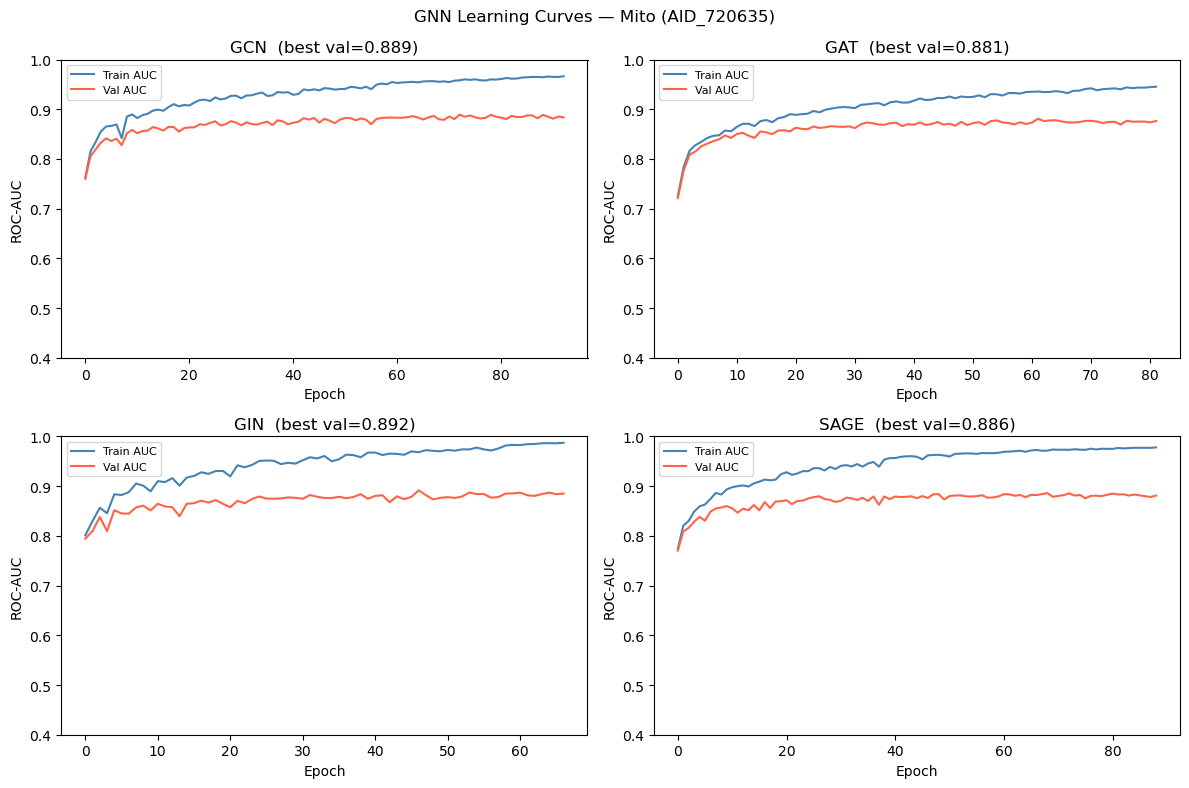

In [69]:
# ── Learning Curves — Mito ───────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, arch in zip(axes.ravel(), ['GCN','GAT','GIN','SAGE']):
    if arch in mito_gnn_history:
        tr, va = mito_gnn_history[arch]
        ax.plot(tr, label='Train AUC', color='steelblue')
        ax.plot(va, label='Val AUC',   color='tomato')
        ax.set_title(f'{arch}  (best val={mito_gnn_val_aucs[arch]:.3f})')
        ax.set_xlabel('Epoch'); ax.set_ylabel('ROC-AUC')
        ax.legend(fontsize=8); ax.set_ylim(0.4, 1.0)
plt.suptitle('GNN Learning Curves — Mito (AID_720635)', fontsize=12)
plt.tight_layout(); plt.savefig('mito_gnn_curves.png', dpi=150); plt.show()

### 2f. Mito Internal Test + Consensus

In [70]:
# ── Mito Internal Test ───────────────────────────────────────────────────
gm_test_ldr   = DataLoader(gm_test, batch_size=BATCH, shuffle=False)
mito_classical = {'Random Forest':best_rf_m, 'SVM':best_svm_m, 'XGBoost':best_xgb_m}

cl_m_test  = {n: clf.predict_proba(X_m_test)[:,1] for n,clf in mito_classical.items()}
gnn_m_test = predict_gnns(mito_gnn_models, mito_gnn_cfgs, gm_test_ldr)

all_m_test = {**cl_m_test, **gnn_m_test}
all_m_test['Consensus']           = np.mean(list(all_m_test.values()), axis=0)
all_m_test['Consensus-Classical'] = np.mean(list(cl_m_test.values()), axis=0)
all_m_test['Consensus-GNN']       = np.mean(list(gnn_m_test.values()), axis=0)

rows = []
for name, prob in all_m_test.items():
    for cpt in [0.5, 0.8]: rows.append(evaluate(y_m_test, prob, name, cpt))
df_mito_test = pd.DataFrame(rows)

print('── Mito Internal Test (CPT=0.5) ──')
display(df_mito_test[df_mito_test.CPT==0.5].set_index('Model')
        [['Sensitivity','Specificity','CCR','ROC-AUC','MCC']].sort_values('ROC-AUC',ascending=False))

── Mito Internal Test (CPT=0.5) ──


,Sensitivity,Specificity,CCR,ROC-AUC,MCC
Model,,,,,
Consensus,85.8,83.5,84.7,0.9147,0.6588
Consensus-GNN,84.4,82.1,83.3,0.9073,0.6303
GIN,84.4,80.1,82.2,0.9005,0.6071
SAGE,84.0,82.4,83.2,0.9001,0.6309
Consensus-Classical,81.9,81.8,81.9,0.8932,0.6055
GCN,82.6,82.0,82.3,0.8924,0.6134
GAT,83.7,81.2,82.4,0.8899,0.6134
Random Forest,81.9,80.2,81.1,0.8893,0.5875
XGBoost,81.2,81.2,81.2,0.8795,0.5922


### 2g. Mito Applicability Domain

In [71]:
# ── AD — k-NN Jaccard ────────────────────────────────────────────────────
nn_ad_m = NearestNeighbors(n_neighbors=5, metric='jaccard', n_jobs=-1)
nn_ad_m.fit(X_m_train)
d_tr_m, _ = nn_ad_m.kneighbors(X_m_train)
md_tr_m   = d_tr_m.mean(axis=1)
ad_thr_m  = md_tr_m.mean() + 1.5*md_tr_m.std()

d_te_m, _ = nn_ad_m.kneighbors(X_m_test)
in_ad_m   = d_te_m.mean(axis=1) <= ad_thr_m

print(f'Mito AD threshold : {ad_thr_m:.4f}')
print(f'Mito Test in AD   : {in_ad_m.sum()}/{len(y_m_test)} ({in_ad_m.mean()*100:.1f}%)')

Mito AD threshold : 0.6504
Mito Test in AD   : 514/925 (55.6%)


---
## Step 3 — HepG2 Caspase 3/7 Model (combined_hepg2_casepase.csv)
### 3a. Load & Curate

In [72]:
# ── Load Caspase HepG2 ───────────────────────────────────────────────────
df_casp_raw = pd.read_csv('/Users/yaminichitikela/Desktop/qsar casepase/caspase/combined_hepg2_casepase.csv',
    usecols=['PUBCHEM_CID','PUBCHEM_EXT_DATASOURCE_SMILES',
             'PUBCHEM_ACTIVITY_SCORE','PUBCHEM_ACTIVITY_OUTCOME'])
print(f'Raw rows : {len(df_casp_raw):,}')
print(df_casp_raw['PUBCHEM_ACTIVITY_OUTCOME'].value_counts())

df_casp_raw['csmi'] = df_casp_raw['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(canonicalize)
df_casp = df_casp_raw.dropna(subset=['csmi']).drop_duplicates('csmi', keep='first').reset_index(drop=True)

df_casp['label'] = df_casp['PUBCHEM_ACTIVITY_SCORE'].apply(
    lambda s: 1 if s>=40 else (0 if s==0 else np.nan))
df_casp = df_casp.dropna(subset=['label']).copy()
df_casp['label'] = df_casp['label'].astype(int)

n_act, n_ina = (df_casp.label==1).sum(), (df_casp.label==0).sum()
print(f'After curate: {len(df_casp):,}  Active={n_act:,}  Inactive={n_ina:,}  Ratio={n_ina/n_act:.1f}:1')

Raw rows : 7,716
PUBCHEM_ACTIVITY_OUTCOME
Inactive        7172
Inconclusive     303
Active           241
Name: count, dtype: int64


[21:03:43] WARNING: not removing hydrogen atom without neighbors


After curate: 7,420  Active=249  Inactive=7,171  Ratio=28.8:1


### 3b. Features

In [73]:
casp_fps = df_casp['csmi'].apply(smiles_to_ecfp4)
valid_c   = casp_fps.notna()
df_casp   = df_casp[valid_c].reset_index(drop=True)
X_casp_all = np.vstack(casp_fps[valid_c].values)
y_casp_all = df_casp['label'].values
print(f'Caspase FP matrix: {X_casp_all.shape}')

graphs_casp_all = [mol_to_graph(s, l) for s, l in zip(df_casp['csmi'].values, y_casp_all)]
print(f'Caspase graphs   : {len(graphs_casp_all)}')

[21:03:43] DEPRECATION WARNING: please use MorganGenerator
[21:03:43] DEPRECATION WARNING: please use MorganGenerator
[21:03:43] DEPRECATION WARNING: please use MorganGenerator
[21:03:43] DEPRECATION WARNING: please use MorganGenerator
[21:03:43] DEPRECATION WARNING: please use MorganGenerator
[21:03:43] DEPRECATION WARNING: please use MorganGenerator
[21:03:43] DEPRECATION WARNING: please use MorganGenerator
[21:03:43] DEPRECATION WARNING: please use MorganGenerator
[21:03:43] DEPRECATION WARNING: please use MorganGenerator
[21:03:43] DEPRECATION WARNING: please use MorganGenerator
[21:03:43] DEPRECATION WARNING: please use MorganGenerator
[21:03:43] DEPRECATION WARNING: please use MorganGenerator
[21:03:43] DEPRECATION WARNING: please use MorganGenerator
[21:03:43] DEPRECATION WARNING: please use MorganGenerator
[21:03:43] DEPRECATION WARNING: please use MorganGenerator
[21:03:43] DEPRECATION WARNING: please use MorganGenerator
[21:03:43] DEPRECATION WARNING: please use MorganGenerat

Caspase FP matrix: (7420, 2048)


[21:03:44] WARNING: not removing hydrogen atom without neighbors


Caspase graphs   : 7420


### 3c. 80/20/20 Split + 3:1 Downsampling

> Caspase has 28.8:1 imbalance — 1:1 leaves only 318 training samples. 3:1 gives 636 samples (tested and found to improve internal AUC from 0.79 → 0.82).

In [74]:
# ── 20% External Test Split ──────────────────────────────────────────────
idx_c = np.arange(len(y_casp_all))
idx_c_pool, idx_c_test = train_test_split(idx_c, test_size=0.20, stratify=y_casp_all, random_state=SEED)

X_c_pool, X_c_test = X_casp_all[idx_c_pool], X_casp_all[idx_c_test]
y_c_pool, y_c_test = y_casp_all[idx_c_pool], y_casp_all[idx_c_test]
gc_pool = [graphs_casp_all[i] for i in idx_c_pool]
gc_test = [graphs_casp_all[i] for i in idx_c_test]

# ── 80/20 Train/Val from Pool ─────────────────────────────────────────────
pool_sub_c = np.arange(len(y_c_pool))
tr_sub_c, val_sub_c = train_test_split(pool_sub_c, test_size=0.20, stratify=y_c_pool, random_state=SEED)

X_c_tr_raw, X_c_val = X_c_pool[tr_sub_c], X_c_pool[val_sub_c]
y_c_tr_raw, y_c_val = y_c_pool[tr_sub_c], y_c_pool[val_sub_c]
gc_val   = [gc_pool[i] for i in val_sub_c]
gc_trraw = [gc_pool[i] for i in tr_sub_c]

# ── 3:1 Downsampling on TRAIN ONLY ───────────────────────────────────────
CASP_DOWNSAMPLE = 3  # 3 inactives per 1 active
rng_c   = np.random.RandomState(SEED)
act_c   = np.where(y_c_tr_raw==1)[0]; ina_c = np.where(y_c_tr_raw==0)[0]
n_keep  = min(CASP_DOWNSAMPLE * len(act_c), len(ina_c))
ina_c_s = rng_c.choice(ina_c, size=n_keep, replace=False)
tr_c_idx = np.concatenate([act_c, ina_c_s]); rng_c.shuffle(tr_c_idx)

X_c_train = X_c_tr_raw[tr_c_idx]; y_c_train = y_c_tr_raw[tr_c_idx]
gc_train  = [gc_trraw[i] for i in tr_c_idx]

actual_ratio = (y_c_train==0).sum()/(y_c_train==1).sum()
print(f'Caspase TRAIN: {len(y_c_train):,}  act={y_c_train.sum()} / ina={(y_c_train==0).sum()}  ratio={actual_ratio:.1f}:1')
print(f'Caspase VAL  : {len(y_c_val):,}  ratio={(y_c_val==0).sum()/(y_c_val==1).sum():.1f}:1')
print(f'Caspase TEST : {len(y_c_test):,}  ratio={(y_c_test==0).sum()/(y_c_test==1).sum():.1f}:1')

Caspase TRAIN: 636  act=159 / ina=477  ratio=3.0:1
Caspase VAL  : 1,188  ratio=28.7:1
Caspase TEST : 1,484  ratio=28.7:1


### 3d. Classical ML — Caspase

In [75]:
# ── Random Forest — Caspase ──────────────────────────────────────────────
best_rf_c_auc, best_rf_c = 0, None
print(f'RF caspase: {len(rf_grid)} configs...')
for p in rf_grid:
    clf = RandomForestClassifier(**p, class_weight='balanced', n_jobs=-1, random_state=SEED)
    clf.fit(X_c_train, y_c_train)
    auc = roc_auc_score(y_c_val, clf.predict_proba(X_c_val)[:,1])
    if auc > best_rf_c_auc: best_rf_c_auc, best_rf_c = auc, clf
print(f'Best RF  casp val AUC={best_rf_c_auc:.4f}')

# ── SVM — Caspase ─────────────────────────────────────────────────────────
best_svm_c_auc, best_svm_c = 0, None
print(f'SVM caspase: {len(svm_grid)} configs...')
for p in svm_grid:
    clf = SVC(**p, kernel='rbf', class_weight='balanced', probability=True, random_state=SEED)
    clf.fit(X_c_train, y_c_train)
    auc = roc_auc_score(y_c_val, clf.predict_proba(X_c_val)[:,1])
    if auc > best_svm_c_auc: best_svm_c_auc, best_svm_c = auc, clf
print(f'Best SVM casp val AUC={best_svm_c_auc:.4f}')

# ── XGBoost — Caspase ────────────────────────────────────────────────────
sw_c = (y_c_train==0).sum()/(y_c_train==1).sum()
best_xgb_c_auc, best_xgb_c = 0, None
print(f'XGB caspase: {len(xgb_grid)} configs...')
for p in xgb_grid:
    clf = XGBClassifier(**p, scale_pos_weight=sw_c, eval_metric='logloss',
                        n_jobs=-1, random_state=SEED, verbosity=0)
    clf.fit(X_c_train, y_c_train)
    auc = roc_auc_score(y_c_val, clf.predict_proba(X_c_val)[:,1])
    if auc > best_xgb_c_auc: best_xgb_c_auc, best_xgb_c = auc, clf
print(f'Best XGB casp val AUC={best_xgb_c_auc:.4f}')

RF caspase: 16 configs...
Best RF  casp val AUC=0.8351
SVM caspase: 9 configs...
Best SVM casp val AUC=0.8643
XGB caspase: 12 configs...
Best XGB casp val AUC=0.8064


### 3e. GNNs — Caspase

In [76]:
casp_gnn_models, casp_gnn_cfgs, casp_gnn_val_aucs, casp_gnn_history = \
    train_gnns(gc_train, gc_val, y_c_train, tag='[CASPASE]')
print('\nCaspase GNNs trained.')


[CASPASE] GCN  (3 configs)
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  val AUC=0.8363  ep=63
  {'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  val AUC=0.8272  ep=50
  {'hidden': 128, 'n_layers': 4, 'dropout': 0.4, 'lr': 0.0005, 'heads': 4}  val AUC=0.8118  ep=100
>> Best GCN: 0.8363

[CASPASE] GAT  (3 configs)
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  val AUC=0.8334  ep=75
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.4, 'lr': 0.0005, 'heads': 8}  val AUC=0.8274  ep=56
  {'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  val AUC=0.8308  ep=29
>> Best GAT: 0.8334

[CASPASE] GIN  (3 configs)
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  val AUC=0.8581  ep=87
  {'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  val AUC=0.8509  ep=87
  {'hidden': 128, 'n_layers': 4, 'dropout': 0.4, 'lr': 0.0005, 'heads': 4}  val AUC=0.8194  ep=53

NameError: name 'casp_gnn_history' is not defined

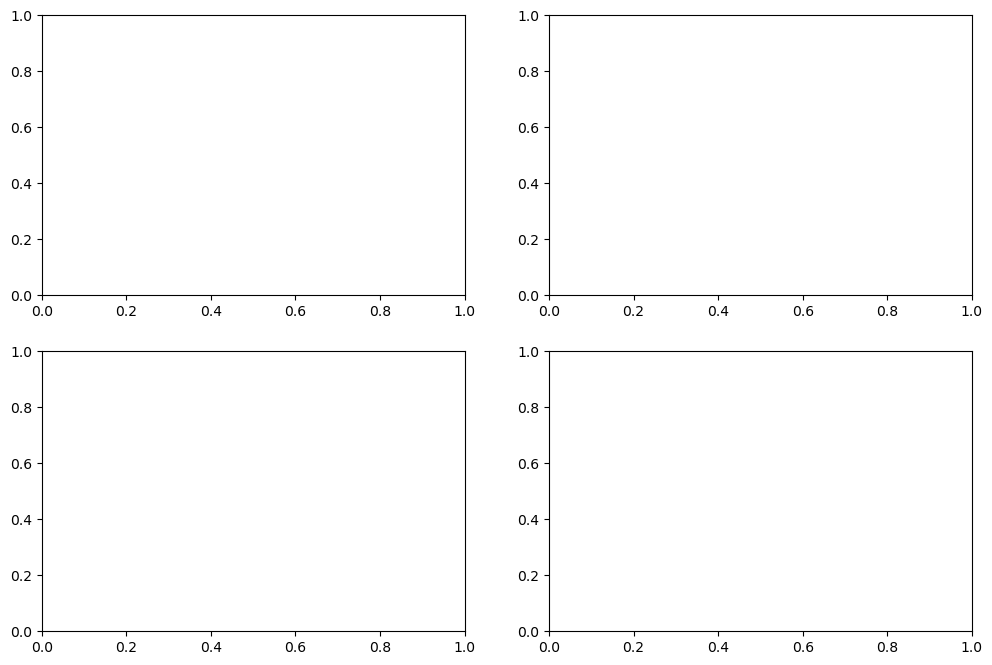

In [15]:
# ── Learning Curves — Caspase ────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, arch in zip(axes.ravel(), ['GCN','GAT','GIN','SAGE']):
    if arch in casp_gnn_history:
        tr, va = casp_gnn_history[arch]
        ax.plot(tr, label='Train AUC', color='steelblue')
        ax.plot(va, label='Val AUC',   color='tomato')
        ax.set_title(f'{arch}  (best val={casp_gnn_val_aucs[arch]:.3f})')
        ax.set_xlabel('Epoch'); ax.set_ylabel('ROC-AUC')
        ax.legend(fontsize=8); ax.set_ylim(0.4, 1.0)
plt.suptitle('GNN Learning Curves — Caspase HepG2', fontsize=12)
plt.tight_layout(); plt.savefig('casp_gnn_curves.png', dpi=150); plt.show()

### 3f. Caspase Internal Test + Consensus

In [16]:
# ── Caspase Internal Test ────────────────────────────────────────────────
gc_test_ldr    = DataLoader(gc_test, batch_size=BATCH, shuffle=False)
casp_classical = {'Random Forest':best_rf_c, 'SVM':best_svm_c, 'XGBoost':best_xgb_c}

cl_c_test  = {n: clf.predict_proba(X_c_test)[:,1] for n,clf in casp_classical.items()}
gnn_c_test = predict_gnns(casp_gnn_models, casp_gnn_cfgs, gc_test_ldr)

all_c_test = {**cl_c_test, **gnn_c_test}
all_c_test['Consensus']           = np.mean(list(all_c_test.values()), axis=0)
all_c_test['Consensus-Classical'] = np.mean(list(cl_c_test.values()), axis=0)
all_c_test['Consensus-GNN']       = np.mean(list(gnn_c_test.values()), axis=0)

rows = []
for name, prob in all_c_test.items():
    for cpt in [0.5, 0.8]: rows.append(evaluate(y_c_test, prob, name, cpt))
df_casp_test = pd.DataFrame(rows)

print('── Caspase Internal Test (CPT=0.5) ──')
display(df_casp_test[df_casp_test.CPT==0.5].set_index('Model')
        [['Sensitivity','Specificity','CCR','ROC-AUC','MCC']].sort_values('ROC-AUC',ascending=False))

NameError: name 'gc_test' is not defined

### 3g. Caspase Applicability Domain

In [79]:
nn_ad_c = NearestNeighbors(n_neighbors=5, metric='jaccard', n_jobs=-1)
nn_ad_c.fit(X_c_train)
d_tr_c, _ = nn_ad_c.kneighbors(X_c_train)
md_tr_c   = d_tr_c.mean(axis=1)
ad_thr_c  = md_tr_c.mean() + 1.5*md_tr_c.std()

d_te_c, _ = nn_ad_c.kneighbors(X_c_test)
in_ad_c   = d_te_c.mean(axis=1) <= ad_thr_c
print(f'Caspase AD threshold : {ad_thr_c:.4f}')
print(f'Caspase Test in AD   : {in_ad_c.sum()}/{len(y_c_test)} ({in_ad_c.mean()*100:.1f}%)')

Caspase AD threshold : 0.6975
Caspase Test in AD   : 684/1484 (46.1%)


---
## Step 4 — External Test Set: In Vivo Liver Injury (LTKB-BD DILI)

Three PubChem bioassays from the FDA's Liver Toxicity Knowledge Base:

| Assay | DILI Category | Description |
|---|---|---|
| AID_625276 | Most-concern | Fatal hepatotoxicity, acute liver failure |
| AID_625277 | Less-concern | Aminotransferases increase, jaundice, cholestasis |
| AID_625278 | No-concern | Negative controls |

**Goal**: Test whether mitotoxicity OR caspase 3/7 activation — or their logical OR combination — translates to in vivo liver injury prediction.

In [80]:
# ── E1. Load & Label Liver DILI Data ─────────────────────────────────────
cols_keep = ['PUBCHEM_CID','PUBCHEM_EXT_DATASOURCE_SMILES',
             'dili_label','dili_source','dili_severity_score']
liver_dfs = []

df76 = pd.read_csv('liver/AID_625276_datatable.csv', low_memory=False)
df76 = df76[df76['Standard Type'] == 'LTKB_BD DILI severity score'].copy()
df76['dili_severity_score'] = pd.to_numeric(df76['Standard Value'], errors='coerce')
df76['dili_label']  = df76['dili_severity_score'].apply(lambda v: 1 if pd.notna(v) else np.nan)
df76['dili_source'] = 'AID_625276 (Most-concern)'
df76 = df76[df76['dili_label'].notna()].copy(); df76['dili_label'] = df76['dili_label'].astype(int)
liver_dfs.append(df76[cols_keep])

df77 = pd.read_csv('liver/AID_625277_datatable.csv', low_memory=False)
df77 = df77[df77['Standard Type'] == 'LTKB_BD DILI severity score'].copy()
df77['dili_severity_score'] = pd.to_numeric(df77['Standard Value'], errors='coerce')
df77['dili_label']  = df77['dili_severity_score'].apply(lambda v: 1 if pd.notna(v) else np.nan)
df77['dili_source'] = 'AID_625277 (Less-concern)'
df77 = df77[df77['dili_label'].notna()].copy(); df77['dili_label'] = df77['dili_label'].astype(int)
liver_dfs.append(df77[cols_keep])

df78 = pd.read_csv('liver/AID_625278_datatable.csv', low_memory=False)
df78 = df78[df78['Standard Type'] == 'LTKB_BD DILI severity score'].copy()
df78['dili_label'] = 0; df78['dili_source'] = 'AID_625278 (No-concern)'; df78['dili_severity_score'] = np.nan
liver_dfs.append(df78[cols_keep])

df_liver = pd.concat(liver_dfs, ignore_index=True)
df_liver['csmi'] = df_liver['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(canonicalize)
df_liver = df_liver.dropna(subset=['csmi']).drop_duplicates('csmi', keep='first').reset_index(drop=True)

print(f'DILI External Test Set')
print(f'  Total: {len(df_liver):,}  DILI+(1): {(df_liver.dili_label==1).sum():,}  DILI-(0): {(df_liver.dili_label==0).sum():,}')
print(df_liver['dili_source'].value_counts().to_string())

DILI External Test Set
  Total: 218  DILI+(1): 157  DILI-(0): 61
dili_source
AID_625277 (Less-concern)    83
AID_625276 (Most-concern)    74
AID_625278 (No-concern)      61


[21:08:40] SMILES Parse Error: syntax error while parsing: nan
[21:08:40] SMILES Parse Error: check for mistakes around position 2:
[21:08:40] nan
[21:08:40] ~^
[21:08:40] SMILES Parse Error: Failed parsing SMILES 'nan' for input: 'nan'
[21:08:40] SMILES Parse Error: syntax error while parsing: nan
[21:08:40] SMILES Parse Error: check for mistakes around position 2:
[21:08:40] nan
[21:08:40] ~^
[21:08:40] SMILES Parse Error: Failed parsing SMILES 'nan' for input: 'nan'
[21:08:40] SMILES Parse Error: syntax error while parsing: nan
[21:08:40] SMILES Parse Error: check for mistakes around position 2:
[21:08:40] nan
[21:08:40] ~^
[21:08:40] SMILES Parse Error: Failed parsing SMILES 'nan' for input: 'nan'
[21:08:40] SMILES Parse Error: syntax error while parsing: nan
[21:08:40] SMILES Parse Error: check for mistakes around position 2:
[21:08:40] nan
[21:08:40] ~^
[21:08:40] SMILES Parse Error: Failed parsing SMILES 'nan' for input: 'nan'
[21:08:40] SMILES Parse Error: syntax error while pa

In [81]:
# ── E2. ECFP4 + Graphs for Liver ─────────────────────────────────────────
liver_fps_raw = df_liver['csmi'].apply(smiles_to_ecfp4)
valid_fp      = liver_fps_raw.notna()
df_liver      = df_liver[valid_fp].reset_index(drop=True)
X_liver       = np.vstack(liver_fps_raw[valid_fp].values)
y_liver       = df_liver['dili_label'].values

graphs_liver, valid_graph_idx = [], []
for i, (smi, lbl) in enumerate(zip(df_liver['csmi'].values, y_liver)):
    g = mol_to_graph(smi, lbl)
    if g is not None:
        graphs_liver.append(g); valid_graph_idx.append(i)

valid_graph_idx = np.array(valid_graph_idx)
X_liver_gnn    = X_liver[valid_graph_idx]
y_liver_gnn    = y_liver[valid_graph_idx]
df_liver_gnn   = df_liver.iloc[valid_graph_idx].reset_index(drop=True)
liver_loader   = DataLoader(graphs_liver, batch_size=BATCH, shuffle=False)

print(f'Liver FP matrix : {X_liver.shape}')
print(f'Liver graphs    : {len(graphs_liver)} / {len(df_liver)}')
print(f'DILI+ in GNN set: {(y_liver_gnn==1).sum()} / {len(y_liver_gnn)}')

Liver FP matrix : (218, 2048)
Liver graphs    : 218 / 218
DILI+ in GNN set: 157 / 218


[21:08:40] DEPRECATION WARNING: please use MorganGenerator
[21:08:40] DEPRECATION WARNING: please use MorganGenerator
[21:08:40] DEPRECATION WARNING: please use MorganGenerator
[21:08:40] DEPRECATION WARNING: please use MorganGenerator
[21:08:40] DEPRECATION WARNING: please use MorganGenerator
[21:08:40] DEPRECATION WARNING: please use MorganGenerator
[21:08:40] DEPRECATION WARNING: please use MorganGenerator
[21:08:40] DEPRECATION WARNING: please use MorganGenerator
[21:08:40] DEPRECATION WARNING: please use MorganGenerator
[21:08:40] DEPRECATION WARNING: please use MorganGenerator
[21:08:40] DEPRECATION WARNING: please use MorganGenerator
[21:08:40] DEPRECATION WARNING: please use MorganGenerator
[21:08:40] DEPRECATION WARNING: please use MorganGenerator
[21:08:40] DEPRECATION WARNING: please use MorganGenerator
[21:08:40] DEPRECATION WARNING: please use MorganGenerator
[21:08:40] DEPRECATION WARNING: please use MorganGenerator
[21:08:40] DEPRECATION WARNING: please use MorganGenerat

Liver in Mito AD    : 98/218 (45.0%)
Liver in Caspase AD : 74/218 (33.9%)
Liver in Either AD  : 126/218


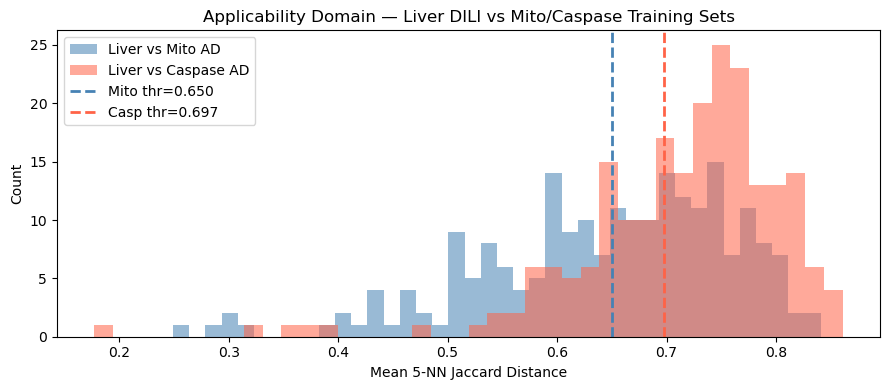

In [82]:
# ── E3. Applicability Domain — Liver vs Both Training Sets ──────────────
d_l_m, _ = nn_ad_m.kneighbors(X_liver); in_ad_liver_m = d_l_m.mean(axis=1) <= ad_thr_m
d_l_c, _ = nn_ad_c.kneighbors(X_liver); in_ad_liver_c = d_l_c.mean(axis=1) <= ad_thr_c

in_ad_liver_m_gnn = in_ad_liver_m[valid_graph_idx]
in_ad_liver_c_gnn = in_ad_liver_c[valid_graph_idx]

print(f'Liver in Mito AD    : {in_ad_liver_m_gnn.sum()}/{len(y_liver_gnn)} ({in_ad_liver_m_gnn.mean()*100:.1f}%)')
print(f'Liver in Caspase AD : {in_ad_liver_c_gnn.sum()}/{len(y_liver_gnn)} ({in_ad_liver_c_gnn.mean()*100:.1f}%)')
print(f'Liver in Either AD  : {(in_ad_liver_m_gnn|in_ad_liver_c_gnn).sum()}/{len(y_liver_gnn)}')

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(d_l_m.mean(axis=1), bins=40, alpha=0.55, color='steelblue', label='Liver vs Mito AD')
ax.hist(d_l_c.mean(axis=1), bins=40, alpha=0.55, color='tomato',    label='Liver vs Caspase AD')
ax.axvline(ad_thr_m, color='steelblue', ls='--', lw=2, label=f'Mito thr={ad_thr_m:.3f}')
ax.axvline(ad_thr_c, color='tomato',    ls='--', lw=2, label=f'Casp thr={ad_thr_c:.3f}')
ax.set_xlabel('Mean 5-NN Jaccard Distance'); ax.set_ylabel('Count')
ax.set_title('Applicability Domain — Liver DILI vs Mito/Caspase Training Sets')
ax.legend(); plt.tight_layout()
plt.savefig('ad_liver_mito_casp.png', dpi=150); plt.show()

---
## Step 5 — Apply Mito & Caspase Models to Liver DILI External Set

In [83]:
# ── E4. Mito predictions on Liver ────────────────────────────────────────
cl_m_liver  = {n: clf.predict_proba(X_liver_gnn)[:,1] for n,clf in mito_classical.items()}
gnn_m_liver = predict_gnns(mito_gnn_models, mito_gnn_cfgs, liver_loader)

all_m_liver = {**cl_m_liver, **gnn_m_liver}
p_mito      = np.mean(list(all_m_liver.values()), axis=0)
p_mito_cl   = np.mean(list(cl_m_liver.values()), axis=0)
p_mito_gnn  = np.mean(list(gnn_m_liver.values()), axis=0)

print(f'Mito consensus on liver: mean={p_mito.mean():.3f}  min={p_mito.min():.3f}  max={p_mito.max():.3f}')

# ── E5. Caspase predictions on Liver ─────────────────────────────────────
cl_c_liver  = {n: clf.predict_proba(X_liver_gnn)[:,1] for n,clf in casp_classical.items()}
gnn_c_liver = predict_gnns(casp_gnn_models, casp_gnn_cfgs, liver_loader)

all_c_liver = {**cl_c_liver, **gnn_c_liver}
p_casp      = np.mean(list(all_c_liver.values()), axis=0)
p_casp_cl   = np.mean(list(cl_c_liver.values()), axis=0)
p_casp_gnn  = np.mean(list(gnn_c_liver.values()), axis=0)

print(f'Casp consensus on liver: mean={p_casp.mean():.3f}  min={p_casp.min():.3f}  max={p_casp.max():.3f}')

Mito consensus on liver: mean=0.403  min=0.010  max=0.961
Casp consensus on liver: mean=0.376  min=0.028  max=0.863


---
## Step 6 — Logical OR Combinations + Stacking

> *"A model that takes logical OR of HepG2 caspase and mitochondrial might capture more causes and lead to better prediction on liver injury."*

- **Hard-OR**: flag DILI=1 if P_mito ≥ CPT **OR** P_casp ≥ CPT
- **Soft-OR (max)**: `max(P_mito, P_casp)` — continuous score
- **Soft-OR (mean)**: `(P_mito + P_casp) / 2`
- **Stacking**: Logistic Regression trained on `[P_mito, P_casp]` via 5-fold CV

In [84]:
# ── Soft-OR ───────────────────────────────────────────────────────────────
p_soft_max  = np.maximum(p_mito, p_casp)
p_soft_mean = (p_mito + p_casp) / 2

# ── Hard-OR: flag if EITHER model exceeds CPT ─────────────────────────────
def hard_or_evaluate(y_true, p_m, p_c, cpt, name):
    y_pred  = ((p_m >= cpt) | (p_c >= cpt)).astype(int)
    p_score = np.maximum(p_m, p_c)
    tn,fp,fn,tp = confusion_matrix(y_true, y_pred).ravel()
    sens = tp/(tp+fn) if (tp+fn)>0 else 0
    spec = tn/(tn+fp) if (tn+fp)>0 else 0
    return {
        'Model':name,'CPT':cpt,
        'DILI+ flagged':int(y_pred.sum()),
        'Sensitivity':round(sens*100,1),'Specificity':round(spec*100,1),
        'CCR':round((sens+spec)/2*100,1),
        'ROC-AUC':round(roc_auc_score(y_true,p_score),4),
        'MCC':round(matthews_corrcoef(y_true,y_pred),4),
        'F1':round(f1_score(y_true,y_pred,zero_division=0),4),
        'TP':int(tp),'TN':int(tn),'FP':int(fp),'FN':int(fn)
    }

print('Hard-OR at different thresholds:')
hor_rows = []
for cpt in [0.3, 0.4, 0.5, 0.6, 0.8]:
    r = hard_or_evaluate(y_liver_gnn, p_mito, p_casp, cpt, f'Hard-OR @{cpt}')
    hor_rows.append(r)
    print(f'  Hard-OR @{cpt}: flagged={r["DILI+ flagged"]}  sens={r["Sensitivity"]}%  '
          f'spec={r["Specificity"]}%  CCR={r["CCR"]}%  ROC-AUC={r["ROC-AUC"]}  MCC={r["MCC"]}')

Hard-OR at different thresholds:
  Hard-OR @0.3: flagged=155  sens=77.1%  spec=44.3%  CCR=60.7%  ROC-AUC=0.6653  MCC=0.2113
  Hard-OR @0.4: flagged=129  sens=63.7%  spec=52.5%  CCR=58.1%  ROC-AUC=0.6653  MCC=0.1475
  Hard-OR @0.5: flagged=103  sens=53.5%  spec=68.9%  CCR=61.2%  ROC-AUC=0.6653  MCC=0.201
  Hard-OR @0.6: flagged=81  sens=43.3%  spec=78.7%  CCR=61.0%  ROC-AUC=0.6653  MCC=0.2044
  Hard-OR @0.8: flagged=34  sens=19.7%  spec=95.1%  CCR=57.4%  ROC-AUC=0.6653  MCC=0.1835


In [85]:
# ── Venn Breakdown: what OR adds vs mito alone ────────────────────────────
print('\n── Venn breakdown at CPT=0.5 ──')
y_mito_05 = (p_mito >= 0.5).astype(int)
y_casp_05 = (p_casp >= 0.5).astype(int)
dili_pos  = y_liver_gnn == 1
dili_neg  = y_liver_gnn == 0

print(f'  Among {dili_pos.sum()} true DILI+ compounds:')
print(f'    Caught by Mito only   : {((y_mito_05==1)&(y_casp_05==0)&dili_pos).sum()}')
print(f'    Caught by Caspase only: {((y_mito_05==0)&(y_casp_05==1)&dili_pos).sum()}  ← OR adds these')
print(f'    Caught by BOTH        : {((y_mito_05==1)&(y_casp_05==1)&dili_pos).sum()}')
print(f'    Missed by BOTH        : {((y_mito_05==0)&(y_casp_05==0)&dili_pos).sum()}  ← OR cannot help')
print(f'\n  Among {dili_neg.sum()} true DILI- compounds (false positives):')
print(f'    Extra FP from Caspase : {((y_mito_05==0)&(y_casp_05==1)&dili_neg).sum()}  ← OR adds these')


── Venn breakdown at CPT=0.5 ──
  Among 157 true DILI+ compounds:
    Caught by Mito only   : 30
    Caught by Caspase only: 19  ← OR adds these
    Caught by BOTH        : 35
    Missed by BOTH        : 73  ← OR cannot help

  Among 61 true DILI- compounds (false positives):
    Extra FP from Caspase : 7  ← OR adds these


In [87]:
# ── Stacking meta-learner (Géron, Chapter 7) ─────────────────────────────
X_meta = np.column_stack([p_mito, p_casp])
scaler = StandardScaler()
X_meta_sc = scaler.fit_transform(X_meta)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
lr = LogisticRegression(C=1.0, class_weight='balanced', max_iter=1000, random_state=SEED)
p_stack = cross_val_predict(lr, X_meta_sc, y_liver_gnn, cv=cv, method='predict_proba')[:,1]

lr_final = LogisticRegression(C=1.0, class_weight='balanced', max_iter=1000, random_state=SEED)
lr_final.fit(X_meta_sc, y_liver_gnn)
_mito_ratio = abs(lr_final.coef_[0,0] / max(abs(lr_final.coef_[0,1]), 0.001))
print(f'Stacking LR coefficients: P_mito={lr_final.coef_[0,0]:.3f}  P_casp={lr_final.coef_[0,1]:.3f}')
print(f'  → Mito weight is {_mito_ratio:.1f}x that of caspase')
print(f'Stacking ROC-AUC (5-fold CV): {roc_auc_score(y_liver_gnn, p_stack):.4f}')

Stacking LR coefficients: P_mito=0.576  P_casp=0.065
  → Mito weight is 8.9x that of caspase
Stacking ROC-AUC (5-fold CV): 0.6648


---
## Step 7 — Full Comparison: All Models on Liver DILI External Set

In [88]:
# ── Evaluate all individual + combination models ─────────────────────────
all_liver_probs = {}

# Individual mito models
for name, prob in {**cl_m_liver, **gnn_m_liver}.items():
    all_liver_probs[f'Mito-{name}'] = prob
all_liver_probs['Mito-Consensus-Classical'] = p_mito_cl
all_liver_probs['Mito-Consensus-GNN']       = p_mito_gnn
all_liver_probs['Mito-Consensus']           = p_mito

# Individual caspase models
for name, prob in {**cl_c_liver, **gnn_c_liver}.items():
    all_liver_probs[f'Casp-{name}'] = prob
all_liver_probs['Casp-Consensus-Classical'] = p_casp_cl
all_liver_probs['Casp-Consensus-GNN']       = p_casp_gnn
all_liver_probs['Casp-Consensus']           = p_casp

# OR combinations
all_liver_probs['Soft-OR (max)']  = p_soft_max
all_liver_probs['Soft-OR (mean)'] = p_soft_mean
all_liver_probs['Stack-2 (LR: Mito+Casp)'] = p_stack

final_rows = []
for name, prob in all_liver_probs.items():
    for cpt in [0.5, 0.8]: final_rows.append(evaluate(y_liver_gnn, prob, name, cpt))

df_liver_final = pd.DataFrame(final_rows)
summary_liver  = (df_liver_final[df_liver_final.CPT==0.5]
                  .set_index('Model').drop(columns='CPT')
                  .sort_values('ROC-AUC', ascending=False))

print('='*90)
print('EXTERNAL TEST — LIVER DILI (LTKB-BD)  |  All Models at CPT=0.50')
print('='*90)
display(summary_liver[['Sensitivity','Specificity','CCR','ROC-AUC','PR-AUC','MCC']])

EXTERNAL TEST — LIVER DILI (LTKB-BD)  |  All Models at CPT=0.50


,Sensitivity,Specificity,CCR,ROC-AUC,PR-AUC,MCC
Model,,,,,,
Mito-GIN,47.1,78.7,62.9,0.6851,0.8422,0.2367
Mito-XGBoost,49.7,80.3,65.0,0.6808,0.8477,0.2736
Mito-Consensus,41.4,80.3,60.9,0.6725,0.8392,0.2041
Mito-Consensus-GNN,40.8,82.0,61.4,0.6666,0.8405,0.2148
Soft-OR (max),53.5,68.9,61.2,0.6653,0.8380,0.2010
Stack-2 (LR: Mito+Casp),57.3,62.3,59.8,0.6648,0.8298,0.1763
Mito-GCN,37.6,85.2,61.4,0.6609,0.8350,0.2212
Mito-Consensus-Classical,45.2,78.7,62.0,0.6593,0.8244,0.2206
Soft-OR (mean),38.2,80.3,59.3,0.6582,0.8284,0.1770


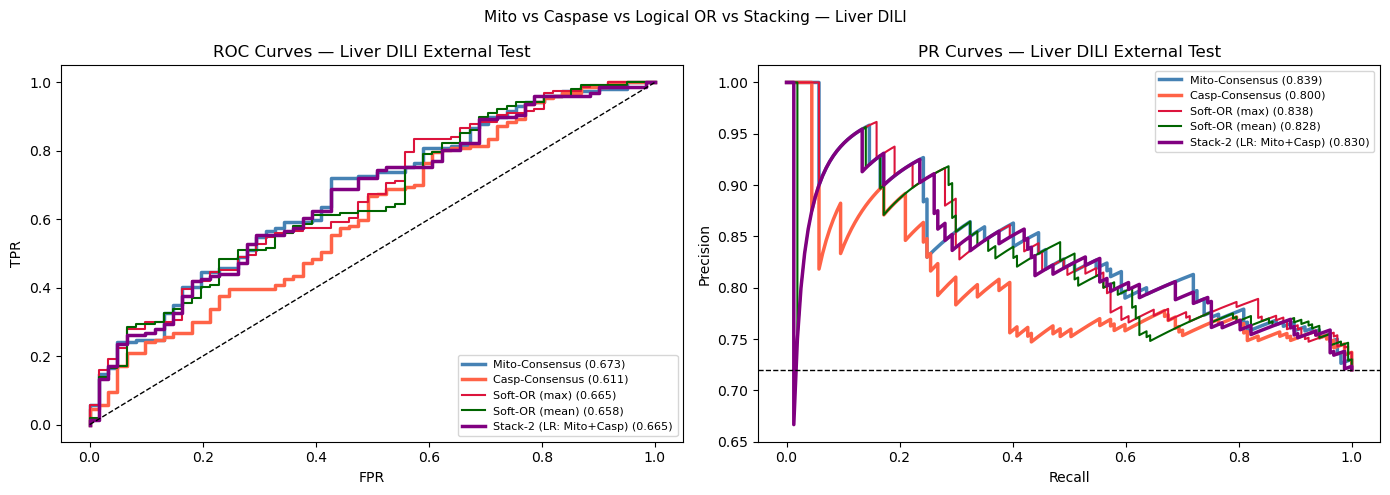

In [89]:
# ── ROC + PR Curves — Key Models ─────────────────────────────────────────
COLORS = {'Mito-Consensus':'steelblue','Casp-Consensus':'tomato',
          'Soft-OR (max)':'crimson','Soft-OR (mean)':'darkgreen',
          'Stack-2 (LR: Mito+Casp)':'purple'}

key_models = {k: all_liver_probs[k] for k in
              ['Mito-Consensus','Casp-Consensus','Soft-OR (max)','Soft-OR (mean)',
               'Stack-2 (LR: Mito+Casp)']}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, prob in key_models.items():
    c = COLORS.get(name,'gray'); lw = 2.5 if 'Consensus' in name or 'Stack' in name else 1.5
    fpr,tpr,_ = roc_curve(y_liver_gnn, prob)
    auc = roc_auc_score(y_liver_gnn, prob)
    axes[0].plot(fpr, tpr, lw=lw, color=c, label=f'{name} ({auc:.3f})')
    pre,rec,_ = precision_recall_curve(y_liver_gnn, prob)
    ap = average_precision_score(y_liver_gnn, prob)
    axes[1].plot(rec, pre, lw=lw, color=c, label=f'{name} ({ap:.3f})')

axes[0].plot([0,1],[0,1],'k--',lw=1)
axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
axes[0].set_title('ROC Curves — Liver DILI External Test')
axes[0].legend(fontsize=8, loc='lower right')
axes[1].axhline(y_liver_gnn.mean(),color='k',ls='--',lw=1)
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('PR Curves — Liver DILI External Test')
axes[1].legend(fontsize=8, loc='upper right')
plt.suptitle('Mito vs Caspase vs Logical OR vs Stacking — Liver DILI', fontsize=11)
plt.tight_layout(); plt.savefig('roc_pr_liver_combined.png', dpi=150); plt.show()

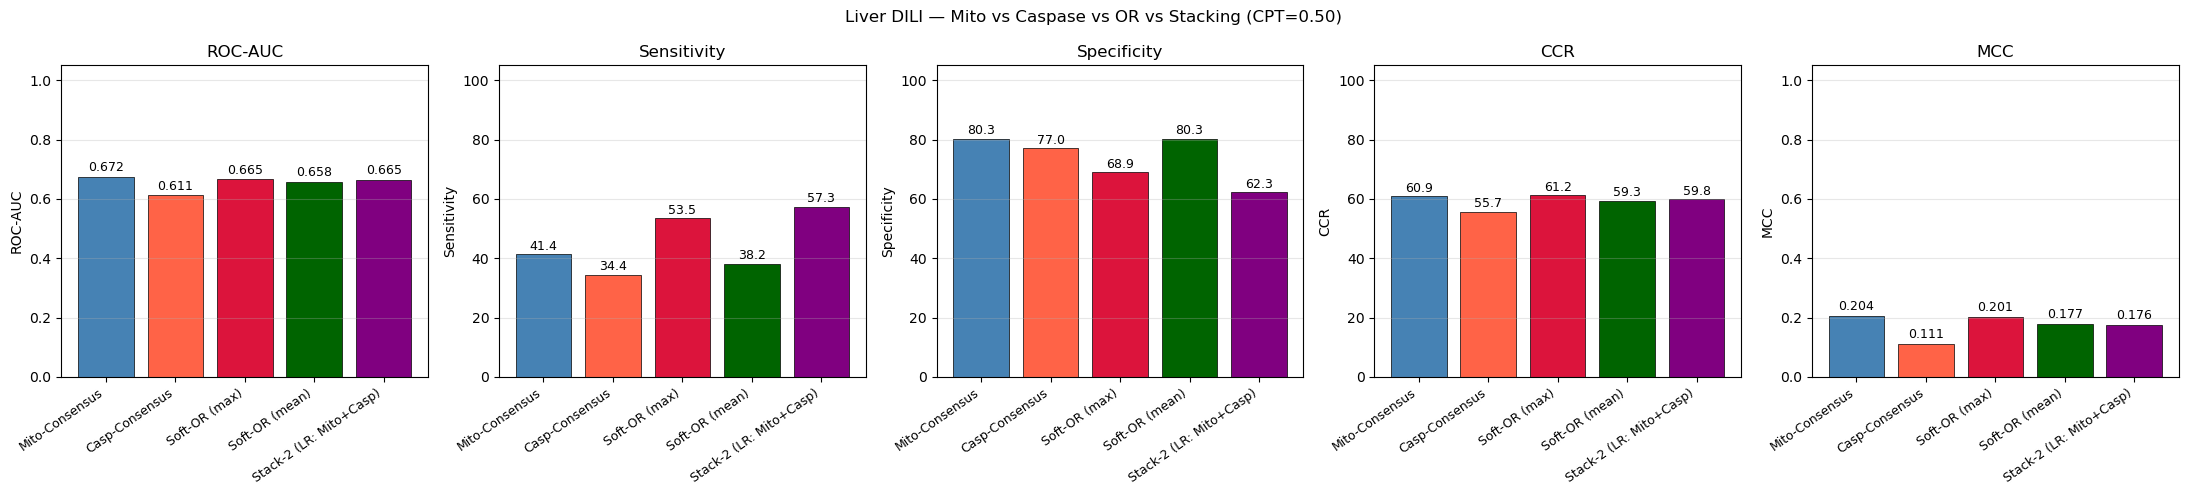

In [90]:
# ── CCR Bar Chart: Key combinations ──────────────────────────────────────
models_bar = ['Mito-Consensus','Casp-Consensus','Soft-OR (max)','Soft-OR (mean)',
              'Stack-2 (LR: Mito+Casp)']
colors_bar = ['steelblue','tomato','crimson','darkgreen','purple']
metrics_b  = ['ROC-AUC','Sensitivity','Specificity','CCR','MCC']

fig, axes = plt.subplots(1, 5, figsize=(22, 5))
for ax, metric in zip(axes, metrics_b):
    vals = [summary_liver.loc[m, metric] if m in summary_liver.index else 0 for m in models_bar]
    ylim = 1.05 if metric in ['ROC-AUC','MCC'] else 105
    bars = ax.bar(range(len(models_bar)), vals, color=colors_bar, edgecolor='k', linewidth=0.5)
    ax.set_xticks(range(len(models_bar)))
    ax.set_xticklabels(models_bar, rotation=35, ha='right', fontsize=9)
    ax.set_ylabel(metric); ax.set_title(metric); ax.set_ylim(0, ylim); ax.grid(axis='y', alpha=0.3)
    for bar, v in zip(bars, vals):
        lbl = f'{v:.3f}' if metric in ['ROC-AUC','MCC'] else f'{v:.1f}'
        ax.text(bar.get_x()+bar.get_width()/2,
                bar.get_height()+(0.01 if metric in ['ROC-AUC','MCC'] else 0.5),
                lbl, ha='center', va='bottom', fontsize=9)
plt.suptitle('Liver DILI — Mito vs Caspase vs OR vs Stacking (CPT=0.50)', fontsize=12)
plt.tight_layout(); plt.savefig('ccr_liver_combined.png', dpi=150); plt.show()

---
## Step 8 — Internal vs External Comparison + Per-Severity Breakdown

In [91]:
# ── Internal vs External Comparison ─────────────────────────────────────
mito_int = df_mito_test[df_mito_test.CPT==0.5].set_index('Model')
casp_int = df_casp_test[df_casp_test.CPT==0.5].set_index('Model')

comp_rows = []
for m in ['Random Forest','SVM','XGBoost','GCN','GAT','GIN','SAGE','Consensus']:
    mi = f'Mito-{m}'; ci = f'Casp-{m}'
    row = {'Model': m}
    if m in mito_int.index:
        row['Mito Internal AUC'] = mito_int.loc[m,'ROC-AUC']
    if mi in summary_liver.index:
        row['Mito Liver AUC']    = summary_liver.loc[mi,'ROC-AUC']
    if m in casp_int.index:
        row['Casp Internal AUC'] = casp_int.loc[m,'ROC-AUC']
    if ci in summary_liver.index:
        row['Casp Liver AUC']    = summary_liver.loc[ci,'ROC-AUC']
    comp_rows.append(row)

df_comp = pd.DataFrame(comp_rows).set_index('Model')
print('='*80)
print('Internal AUC vs External Liver DILI AUC')
print('='*80)
display(df_comp)

Internal AUC vs External Liver DILI AUC


,Mito Internal AUC,Mito Liver AUC,Casp Internal AUC,Casp Liver AUC
Model,,,,
Random Forest,0.8893,0.6373,0.7944,0.5886
SVM,0.8763,0.6341,0.8352,0.5800
XGBoost,0.8795,0.6808,0.7650,0.5795
GCN,0.8924,0.6609,0.7788,0.6201
GAT,0.8899,0.6465,0.7839,0.6275
GIN,0.9005,0.6851,0.8038,0.6041
SAGE,0.9001,0.6459,0.7679,0.6225
Consensus,0.9147,0.6725,0.8238,0.6114


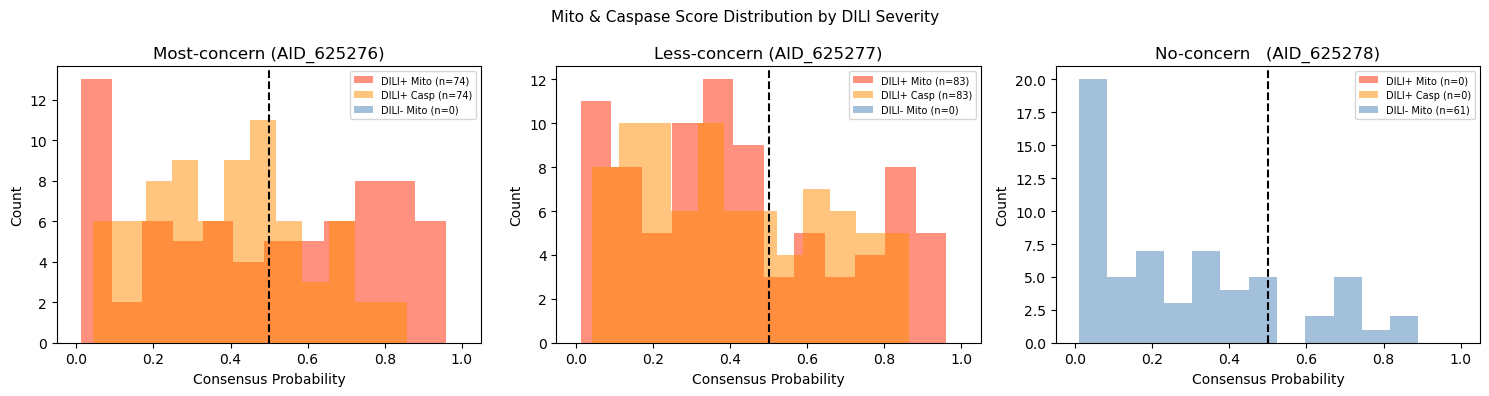


Spearman ρ with DILI severity score:
  Mito consensus : ρ=0.034  p=0.6737
  Casp consensus : ρ=-0.021  p=0.7980
  Soft-OR (max)  : ρ=0.075  p=0.3531


In [92]:
# ── Per-Severity Breakdown ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
categories = {
    'Most-concern (AID_625276)': df_liver_gnn['dili_source'].str.contains('AID_625276'),
    'Less-concern (AID_625277)': df_liver_gnn['dili_source'].str.contains('AID_625277'),
    'No-concern   (AID_625278)': df_liver_gnn['dili_source'].str.contains('AID_625278'),
}
for ax, (title, mask) in zip(axes, categories.items()):
    mask_arr = mask.values
    ax.hist(p_mito[mask_arr & (y_liver_gnn==1)], bins=12, alpha=0.7, color='tomato',
            label=f'DILI+ Mito (n={(mask_arr&(y_liver_gnn==1)).sum()})')
    ax.hist(p_casp[mask_arr & (y_liver_gnn==1)], bins=12, alpha=0.5, color='darkorange',
            label=f'DILI+ Casp (n={(mask_arr&(y_liver_gnn==1)).sum()})')
    ax.hist(p_mito[mask_arr & (y_liver_gnn==0)], bins=12, alpha=0.5, color='steelblue',
            label=f'DILI- Mito (n={(mask_arr&(y_liver_gnn==0)).sum()})')
    ax.axvline(0.5, color='black', ls='--', lw=1.5)
    ax.set_xlabel('Consensus Probability'); ax.set_ylabel('Count')
    ax.set_title(title); ax.legend(fontsize=7)
plt.suptitle('Mito & Caspase Score Distribution by DILI Severity', fontsize=11)
plt.tight_layout(); plt.savefig('liver_severity_breakdown.png', dpi=150); plt.show()

# Spearman correlation with severity score
sev_mask = df_liver_gnn['dili_severity_score'].notna()
if sev_mask.sum() > 5:
    sev_scores = df_liver_gnn.loc[sev_mask, 'dili_severity_score'].values
    rho_m, p_m = spearmanr(sev_scores, p_mito[sev_mask.values])
    rho_c, p_c = spearmanr(sev_scores, p_casp[sev_mask.values])
    rho_or,p_or= spearmanr(sev_scores, p_soft_max[sev_mask.values])
    print(f'\nSpearman ρ with DILI severity score:')
    print(f'  Mito consensus : ρ={rho_m:.3f}  p={p_m:.4f}')
    print(f'  Casp consensus : ρ={rho_c:.3f}  p={p_c:.4f}')
    print(f'  Soft-OR (max)  : ρ={rho_or:.3f}  p={p_or:.4f}')

---
## Step 9 — Final Summary & Save

In [93]:
# ── Master Summary Table ─────────────────────────────────────────────────
print('='*100)
print('FINAL ANSWER: Does logical OR of Mito + Caspase improve Liver DILI prediction?')
print('='*100)

key_summary_models = ['Mito-Consensus','Casp-Consensus','Soft-OR (max)','Soft-OR (mean)',
                      'Stack-2 (LR: Mito+Casp)']
df_final_summary = summary_liver.loc[
    [m for m in key_summary_models if m in summary_liver.index],
    ['Sensitivity','Specificity','CCR','ROC-AUC','PR-AUC','MCC','Bal-Acc','F1']
]
display(df_final_summary)

best_roc = df_final_summary['ROC-AUC'].idxmax()
best_ccr = df_final_summary['CCR'].idxmax()
best_mcc = df_final_summary['MCC'].idxmax()
print(f'\nBest ROC-AUC : {best_roc}  ({df_final_summary.loc[best_roc,"ROC-AUC"]:.4f})')
print(f'Best CCR     : {best_ccr}  ({df_final_summary.loc[best_ccr,"CCR"]:.1f}%)')
print(f'Best MCC     : {best_mcc}  ({df_final_summary.loc[best_mcc,"MCC"]:.4f})')

print(f'\nLR coefficients: P_mito={lr_final.coef_[0,0]:.3f}  P_casp={lr_final.coef_[0,1]:.3f}')
print('  → Quantifies how much each model contributes to liver DILI prediction')

# Hard-OR summary
print('\nHard-OR at all thresholds:')
for r in hor_rows:
    print(f'  {r["Model"]}: flagged={r["DILI+ flagged"]}  sens={r["Sensitivity"]}%  '
          f'spec={r["Specificity"]}%  CCR={r["CCR"]}%  AUC={r["ROC-AUC"]}')

# Save
df_liver_final.to_csv('combined_mito_caspase_liver_results.csv', index=False)
print('\nSaved → combined_mito_caspase_liver_results.csv')

FINAL ANSWER: Does logical OR of Mito + Caspase improve Liver DILI prediction?


,Sensitivity,Specificity,CCR,ROC-AUC,PR-AUC,MCC,Bal-Acc,F1
Model,,,,,,,,
Mito-Consensus,41.4,80.3,60.9,0.6725,0.8392,0.2041,60.9,0.5556
Casp-Consensus,34.4,77.0,55.7,0.6114,0.7996,0.1109,55.7,0.4800
Soft-OR (max),53.5,68.9,61.2,0.6653,0.8380,0.2010,61.2,0.6462
Soft-OR (mean),38.2,80.3,59.3,0.6582,0.8284,0.1770,59.3,0.5240
Stack-2 (LR: Mito+Casp),57.3,62.3,59.8,0.6648,0.8298,0.1763,59.8,0.6667



Best ROC-AUC : Mito-Consensus  (0.6725)
Best CCR     : Soft-OR (max)  (61.2%)
Best MCC     : Mito-Consensus  (0.2041)

LR coefficients: P_mito=0.576  P_casp=0.065
  → Quantifies how much each model contributes to liver DILI prediction

Hard-OR at all thresholds:
  Hard-OR @0.3: flagged=155  sens=77.1%  spec=44.3%  CCR=60.7%  AUC=0.6653
  Hard-OR @0.4: flagged=129  sens=63.7%  spec=52.5%  CCR=58.1%  AUC=0.6653
  Hard-OR @0.5: flagged=103  sens=53.5%  spec=68.9%  CCR=61.2%  AUC=0.6653
  Hard-OR @0.6: flagged=81  sens=43.3%  spec=78.7%  CCR=61.0%  AUC=0.6653
  Hard-OR @0.8: flagged=34  sens=19.7%  spec=95.1%  CCR=57.4%  AUC=0.6653

Saved → combined_mito_caspase_liver_results.csv


---
## Step 10 — Figure 3B: Toxicophore IVIVC (Mito + Caspase vs DILI)

Even with mito+caspase combined, external AUC ~0.67 — because DILI has multiple mechanisms.
This Figure 3B shows **where** the model works (which toxicophore classes) and where it fails.

Three predictors evaluated against DILI in vivo:
- **Mito consensus** (in vitro AID 720635)
- **Caspase consensus** (in vitro HepG2 caspase 3/7)
- **Soft-OR (max)** — combined: active if either model says active

The Soft-OR has the highest sensitivity (53.5%) — catches more DILI compounds at the cost of more FP.

In [1]:
# -- Step 10a. Figure 3B: Toxicophore IVIVC for Mito vs Caspase vs Combined --
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.Chem.Draw import rdMolDraw2D
from scipy.stats import fisher_exact, chi2_contingency
from PIL import Image
from io import BytesIO
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches

COLORS = {'TP':'#2166ac','TN':'#4dac26','FP':'#b8e186','FN':'#d6604d'}

# Predictors: each is a probability array over y_liver_gnn compounds
# df_liver_gnn is the subset of df_liver with valid GNN features
df_ev = df_liver.iloc[:len(y_liver_gnn)].copy().reset_index(drop=True)
df_ev['y_true']    = y_liver_gnn
df_ev['pred_mito'] = (p_mito >= 0.5).astype(int)
df_ev['pred_casp'] = (p_casp >= 0.5).astype(int)
df_ev['pred_or']   = (p_soft_max >= 0.5).astype(int)
df_ev['mol']       = df_ev['csmi'].apply(lambda s: Chem.MolFromSmiles(str(s)))

def classify(true, pred):
    if   true==1 and pred==1: return 'TP'
    elif true==0 and pred==0: return 'TN'
    elif true==0 and pred==1: return 'FP'
    else:                     return 'FN'

toxicophores = [
    {'name':'Nitroaromatic',        'smarts':'[c][N+](=O)[O-]'},
    {'name':'Halogenated aromatic', 'smarts':'[c][F,Cl,Br,I]'},
    {'name':'Michael acceptor',     'smarts':'C=CC(=O)[#6,#7,#8]'},
    {'name':'Cationic amphiphile',  'smarts':'[N+;!$(NC=O)]'},
    {'name':'Phenol (uncoupler)',   'smarts':'[OH]c1ccccc1'},
    {'name':'Epoxide',             'smarts':'C1OC1'},
]

bg_rate = df_ev['y_true'].mean()

# Enrichment screen — pick top-4 by DILI enrichment with enough n
top_tox = []
for tox in toxicophores:
    qmol = Chem.MolFromSmarts(tox['smarts'])
    if qmol is None: continue
    mask = df_ev['mol'].apply(lambda m: bool(m) and m.HasSubstructMatch(qmol))
    sub  = df_ev[mask]
    if len(sub) < 10: continue
    n_act = sub['y_true'].sum()
    enrich = (n_act/len(sub)) / (bg_rate+1e-8)
    bg_act = df_ev['y_true'].sum() - n_act
    bg_ina = len(df_ev) - len(sub) - bg_act
    _, pval = fisher_exact([[n_act, len(sub)-n_act],[bg_act, bg_ina]], alternative='greater')
    top_tox.append({**tox, 'n':len(sub), 'n_act':int(n_act),
                    'enrich':enrich, 'pval':pval, 'mask':mask})

top_tox = sorted(top_tox, key=lambda x: -x['enrich'])[:4]
print(f'Top toxicophores: {[t["name"] for t in top_tox]}')

# ── Figure: 3 rows (mito/casp/OR) × 4 cols (toxicophores) ──────────────────
predictors = [
    ('Mito\nConsensus',   'pred_mito', '#2171b5'),
    ('Caspase\nConsensus','pred_casp', '#6a3d9a'),
    ('Soft-OR\n(Mito|Casp)', 'pred_or', '#d62728'),
]
n_pred = len(predictors)
n_cols = len(top_tox)

fig = plt.figure(figsize=(5 * n_cols, 4 * n_pred + 2.5))
# Top row: molecule images
gs_mol = gridspec.GridSpec(1, n_cols, figure=fig,
                            top=0.97, bottom=0.97 - 0.15, hspace=0.05)
# Bar rows: one per predictor
row_h   = (0.97 - 0.15 - 0.08) / n_pred
gs_bars = []
for pi in range(n_pred):
    top_frac = 0.97 - 0.15 - 0.03 - pi * row_h
    bot_frac = top_frac - row_h + 0.04
    gs_bars.append(gridspec.GridSpec(1, n_cols, figure=fig,
                                     top=top_frac, bottom=bot_frac, hspace=0.05))

for ci, tox in enumerate(top_tox):
    sub    = df_ev[tox['mask']].copy()
    qmol   = Chem.MolFromSmarts(tox['smarts'])
    max_n  = len(sub)

    # Molecule panel
    ax_mol = fig.add_subplot(gs_mol[0, ci])
    drawn  = False
    for smi in sub['csmi'].head(30):
        mol = Chem.MolFromSmiles(str(smi))
        if mol and mol.HasSubstructMatch(qmol):
            match = list(mol.GetSubstructMatch(qmol))
            try:
                drawer = rdMolDraw2D.MolDraw2DCairo(220, 140)
                drawer.drawOptions().addAtomIndices = False
                rdMolDraw2D.PrepareAndDrawMolecule(
                    drawer, mol, highlightAtoms=match,
                    highlightAtomColors={a:(0.9,0.2,0.2) for a in match})
                drawer.FinishDrawing()
                ax_mol.imshow(Image.open(BytesIO(drawer.GetDrawingText())))
                drawn = True; break
            except: continue
    if not drawn:
        ax_mol.text(0.5,0.5,tox['name'],ha='center',va='center',transform=ax_mol.transAxes)
    ax_mol.axis('off')
    ax_mol.set_title(
        f"{tox['name']}\nn={tox['n']}  enrich={tox['enrich']:.2f}x  p={tox['pval']:.3f}",
        fontsize=9, fontweight='bold'
    )

    # Bar panels — one per predictor
    for pi, (p_label, p_col, p_color) in enumerate(predictors):
        sub['cls'] = sub.apply(lambda r: classify(r['y_true'], r[p_col]), axis=1)
        cnt = sub['cls'].value_counts()
        tp=int(cnt.get('TP',0)); tn=int(cnt.get('TN',0))
        fp=int(cnt.get('FP',0)); fn=int(cnt.get('FN',0))
        ccr = (tp+tn)/max_n if max_n>0 else 0
        ct  = np.array([[tp,fn],[fp,tn]])
        try:    _,pv,_,_ = chi2_contingency(ct, correction=False)
        except: pv = 1.0

        ax = fig.add_subplot(gs_bars[pi][0, ci])
        w  = 0.5
        ax.bar(0, tp, w, color=COLORS['TP'])
        ax.bar(0, fn, w, bottom=tp,    color=COLORS['FN'])
        ax.bar(0, fp, w, bottom=tp+fn, color=COLORS['FP'])
        ax.bar(0, tn, w, bottom=tp+fn+fp, color=COLORS['TN'])
        for val, bot in [(tp,0),(fn,tp),(fp,tp+fn),(tn,tp+fn+fp)]:
            if val>0:
                ax.text(0, bot+val/2, str(val), ha='center', va='center',
                        fontsize=8, color='white', fontweight='bold')
        ax.set_xticks([0])
        ax.set_xticklabels([p_label], fontsize=8)
        ax.set_xlim(-0.5, 0.5)
        ax.set_ylim(0, max_n * 1.25)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        dy = max_n * 0.12
        ax.text(0, -dy,   f'CCR={ccr:.2f}', ha='center', fontsize=8)
        pstr = f'p={pv:.3f}' if pv>=0.001 else f'p={pv:.1e}'
        ax.text(0, -dy*2, pstr, ha='center', fontsize=8,
                color='#d62728' if pv<0.05 else 'gray')
        if ci == 0:
            ax.set_ylabel(p_label.replace('\n',' ')+' vs DILI', fontsize=8)

        print(f"  {tox['name']:25s} | {p_label.replace(chr(10),' '):20s} "
              f"TP={tp:3d} TN={tn:3d} FP={fp:3d} FN={fn:3d} CCR={ccr:.2f} p={pv:.4f}")

handles = [mpatches.Patch(color=COLORS[k],label=k) for k in ['TP','TN','FP','FN']]
fig.legend(handles=handles, loc='upper right', fontsize=9,
           title='vs DILI in vivo', bbox_to_anchor=(0.99,0.99))
fig.suptitle(
    'Figure 3B: Mito vs Caspase vs Combined — IVIVC for confirmed toxicophores\n'
    'Ground truth: DILI liver damage (in vivo)  |  Each row = one predictor',
    fontsize=11, y=0.995
)
plt.savefig('figure3b_mito_casp_combined_ivivc.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved => figure3b_mito_casp_combined_ivivc.png')

NameError: name 'df_liver' is not defined

In [ ]:
# -- Step 10b. Why is AUC still ~0.67? What each model adds ------------------
# Shows which DILI compounds only mito catches, only caspase catches, both, neither
import matplotlib.pyplot as plt
import numpy as np

pred_m = (p_mito     >= 0.5).astype(int)
pred_c = (p_casp     >= 0.5).astype(int)
y      = y_liver_gnn

# Among truly DILI+ compounds, how many does each model catch?
pos_mask  = y == 1
neg_mask  = y == 0
n_pos     = pos_mask.sum()
n_neg     = neg_mask.sum()

only_mito  = ((pred_m==1) & (pred_c==0) & pos_mask).sum()
only_casp  = ((pred_m==0) & (pred_c==1) & pos_mask).sum()
both       = ((pred_m==1) & (pred_c==1) & pos_mask).sum()
neither    = ((pred_m==0) & (pred_c==0) & pos_mask).sum()

fp_only_m  = ((pred_m==1) & (pred_c==0) & neg_mask).sum()
fp_only_c  = ((pred_m==0) & (pred_c==1) & neg_mask).sum()
fp_both    = ((pred_m==1) & (pred_c==1) & neg_mask).sum()

print(f'DILI+ compounds (n={n_pos}):')
print(f'  Both models active  : {both:3d} ({100*both/n_pos:.1f}%)  <- strong mito+caspase signal')
print(f'  Only Mito active    : {only_mito:3d} ({100*only_mito/n_pos:.1f}%)  <- mito mechanism, no caspase')
print(f'  Only Caspase active : {only_casp:3d} ({100*only_casp/n_pos:.1f}%)  <- caspase mechanism, no mito')
print(f'  Neither active      : {neither:3d} ({100*neither/n_pos:.1f}%)  <- other DILI mechanism entirely')
print()
print(f'DILI- compounds (n={n_neg}) false alarms:')
print(f'  Both flag as active : {fp_both:3d} ({100*fp_both/n_neg:.1f}%)')
print(f'  Only Mito flags     : {fp_only_m:3d} ({100*fp_only_m/n_neg:.1f}%)')
print(f'  Only Caspase flags  : {fp_only_c:3d} ({100*fp_only_c/n_neg:.1f}%)')

# Venn-style bar chart
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
labels = ['Both\n(mito+casp)', 'Mito only', 'Caspase only', 'Neither\ncaptured']
vals   = [both, only_mito, only_casp, neither]
colors = ['#2166ac','#4393c3','#6a3d9a','#d62728']
bars   = ax.bar(labels, vals, color=colors, edgecolor='k', linewidth=0.5)
for b, v in zip(bars, vals):
    ax.text(b.get_x()+b.get_width()/2, v+0.5, f'{v}\n({100*v/n_pos:.0f}%)',
            ha='center', fontsize=9)
ax.set_ylabel('DILI+ compounds correctly detected')
ax.set_title(f'Which DILI+ compounds does each model catch?\n(n={n_pos} total hepatotoxic)', fontsize=10)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)

ax2 = axes[1]
sens_m   = (pred_m[pos_mask]==1).mean()
sens_c   = (pred_c[pos_mask]==1).mean()
sens_or  = (((pred_m|pred_c)==1)[pos_mask]).mean()
spec_m   = (pred_m[neg_mask]==0).mean()
spec_c   = (pred_c[neg_mask]==0).mean()
spec_or  = (((pred_m|pred_c)==0)[neg_mask]).mean()

x = np.arange(3)
ax2.bar(x-0.2, [sens_m, sens_c, sens_or], 0.35,
        color=['#4393c3','#6a3d9a','#d62728'], label='Sensitivity', alpha=0.9)
ax2.bar(x+0.2, [spec_m, spec_c, spec_or], 0.35,
        color=['#4393c3','#6a3d9a','#d62728'], label='Specificity', alpha=0.5)
ax2.set_xticks(x)
ax2.set_xticklabels(['Mito\nConsensus','Caspase\nConsensus','Soft-OR\n(Mito|Casp)'])
ax2.set_ylabel('Rate')
ax2.set_ylim(0, 1.1)
ax2.set_title('Sensitivity vs Specificity tradeoff\n(dark=sensitivity, light=specificity)', fontsize=10)
ax2.legend(fontsize=9)
ax2.spines['top'].set_visible(False); ax2.spines['right'].set_visible(False)
for bars_list in [ax2.containers[0], ax2.containers[1]]:
    for b in bars_list:
        h = b.get_height()
        ax2.text(b.get_x()+b.get_width()/2, h+0.01, f'{h:.2f}', ha='center', fontsize=7)

fig.suptitle(
    f'Why AUC~0.67: mito+caspase explain {100*(both+only_mito+only_casp)/n_pos:.0f}% of DILI+ compounds\n'
    f'{100*neither/n_pos:.0f}% of DILI cases involve mechanisms other than mito or caspase',
    fontsize=11
)
plt.tight_layout()
plt.savefig('ivivc_mechanism_gap_mito_casp.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved => ivivc_mechanism_gap_mito_casp.png')